# 06 — Behaviour landscape, energy landscape and recurrent motifs

End-to-end tutorial for the landscape API (`scjdo2.landscape`) on the
equilibrated toggle-switch pitchfork, where the true dynamics are known.

What this notebook does:

1. generate the equilibrated pitchfork snapshot (`scjdo2.data.synthetic_pitchfork`)
2. fit the energy-parameterised score drift and read the per-cell latent operator `J = −β ∇²E`
3. run `scjdo2.landscape.analyse` — oracle tolerance, operator-space invariants, lead-eig basin classes,
   eigenvalue-sign fractions, well stiffness, energy, recurrent motifs
4. build a scrambled null (`scjdo2.opspace.flow_scrambled_null`)
5. render every figure with `scjdo2.landscape.figures`

Everything is computed from scratch here, so the numbers differ slightly from the
locked benchmark tables in `SUMMARY.md` (fewer epochs, smaller latent); the point
is the workflow, not the values.

**Caveat carried by every figure.** On a snapshot the operator is the Hessian of
the learned log density, so basins are where cells pile up and are held, forks are
density saddles; it is not the dynamics Jacobian except near stable states. The
pitchfork is used precisely because the analytic Jacobian is available to check that.

In [1]:
import warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import scjdo2
from scjdo2 import opspace, landscape
from scjdo2.data.synthetic_pitchfork import generate_pitchfork_equilibrated, analytic_jacobian
from scjdo2.energy_drift import EnergyDriftAdapter, EnergyDriftConfig

warnings.filterwarnings("ignore", category=FutureWarning)
OUT = Path("../benchmarks/v2/tutorial_06")
OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
np.random.seed(SEED)
print(scjdo2.__version__ if hasattr(scjdo2, "__version__") else "scjdo2")

0.1.0.dev1


## 1. Data — equilibrated pitchfork

A mixture of stationary densities across an α-ramp through the bifurcation at
`τ_crit = 0.3`. Each cell carries its true 2-D state (`obsm["X_true"]`), the
true drift (`obsm["V_true"]`) and the analytic Jacobian, which we use below as
ground truth for the behaviour classes.

We add three labels the figures use: a `cluster` (upper branch / lower branch /
saddle region, from the true state), a `condition` (early vs late along the ramp,
standing in for young vs aged), and a `donor` (random thirds, the replicate unit
for the motif null).

In [2]:
adata = generate_pitchfork_equilibrated(tau_crit=0.3, n_cells=1200, n_genes=200,
                                        n_latent=20, seed=SEED)
Xt = adata.obsm["X_true"]
pt = adata.obs["pseudotime"].to_numpy()

# ground truth from the analytic Jacobian
Jt = analytic_jacobian(Xt, adata.obs["alpha"].to_numpy())
lead_true = np.linalg.eigvals(Jt).real.max(axis=1)
adata.obs["lead_re_true"] = lead_true

# labels
diff = Xt[:, 0] - Xt[:, 1]
cluster = np.where(np.abs(diff) < 0.35, "saddle", np.where(diff > 0, "upper", "lower"))
adata.obs["cluster"] = pd.Categorical(cluster)
adata.obs["condition"] = pd.Categorical(np.where(pt < 0.5, "early", "late"))
rng = np.random.default_rng(SEED)
adata.obs["donor"] = pd.Categorical(rng.choice(["d1", "d2", "d3"], size=adata.n_obs))
adata.uns["scjdo2"] = {"meta": {"use_rep": "X_pca", "clock_calibrated": False}}
adata

AnnData object with n_obs × n_vars = 1200 × 200
    obs: 'pseudotime', 'alpha', 'lead_re_true', 'cluster', 'condition', 'donor'
    uns: 'pitchfork', 'scjdo2'
    obsm: 'X_true', 'V_true', 'X_pca'

## 2. Energy drift and the latent operator

`EnergyDriftAdapter` learns a scalar `E(z)` by exact (Hyvärinen) score matching;
the score is `−∇E`, the drift `β·score`, and the per-cell operator is
`J = −β ∇²E`, symmetric by construction. A few hundred epochs are enough for the
tutorial; the benchmark runs use 2000.

In [3]:
z = np.asarray(adata.obsm["X_pca"], dtype=np.float32)
t0 = time.time()
drift = EnergyDriftAdapter(dim=z.shape[1], config=EnergyDriftConfig(
    n_epochs=2000, hidden=96, depth=3, seed=SEED, device="cpu")).fit(z)
J = drift.jacobian_autodiff(z)
adata.obsm["X_drift_v"] = drift.velocity(z)
adata.uns["scjdo2"]["J"] = J
sym = drift.symmetry_check(z)
print(f"fit {time.time()-t0:.0f}s; J shape {J.shape}; median asymmetry {sym['median_asym']:.1e}")

fit 148s; J shape (1200, 20, 20); median asymmetry 8.9e-08


## 3. One-call analysis

`landscape.analyse` fixes the order: oracle tolerance → operator-space
invariants → lead-eig basin classes and `basin_index` → eigenvalue-sign
fractions → well stiffness → energy → motifs. Every step is also a public
function you can call on its own (`opspace.oracle_tol`,
`opspace.behaviour_fractions`, `opspace.well_stiffness`, `opspace.store_energy`,
`motifs.fit_motifs`, …).

In [4]:
info = landscape.analyse(
    adata, cluster_key="cluster", resting_types=("upper", "lower"),
    drift=drift, motifs=True, replicate_key="donor", n_perm=100, seed=SEED, verbose=True,
)
info

[landscape] tol = 0.003731


/home/claude/manarai/scjdo2/scjdo2/landscape.py:127: RuntimeWarning: spectrum(fisher_mask=True) called without a Fisher ledger; falling back to no mask. Phase B latent runs have no ledger; Phase C stores one when the gene-space pipeline runs.
  _opspace.spectrum(adata, n_eig=min(5, Jd.shape[1]))


[landscape] motifs: K = 2


{'use_rep': 'X_pca', 'tol': 0.003731326071354961, 'energy': True, 'K': 2}

In [5]:
# what got written
cols = ["lead_re", "spectral_gap", "henrici", "op_behaviour_basin", "op_basin_index",
        "op_frac_neg", "op_frac_zero", "op_frac_pos", "op_stiffness", "energy", "op_motif"]
adata.obs[cols].head()

,lead_re,spectral_gap,henrici,op_behaviour_basin,op_basin_index,op_frac_neg,op_frac_zero,op_frac_pos,op_stiffness,energy,op_motif
c00000,0.017241,0.014673,0.938869,fork,-0.017241,0.90,0.05,0.05,0.612715,15.886606,1
c00001,-0.001066,0.022282,0.939500,drift,0.001066,0.95,0.05,0.00,0.644080,13.858583,0
c00002,-0.008787,0.044025,0.938564,holder,0.008787,1.00,0.00,0.00,0.618992,11.100643,0
c00003,-0.011900,0.022388,0.946802,holder,0.011900,1.00,0.00,0.00,0.591080,11.059512,0
c00004,-0.020033,0.015073,0.942768,holder,0.020033,1.00,0.00,0.00,0.635457,14.602697,0


### Check against the analytic truth

The learned `lead_re` should track the analytic leading eigenvalue, and the
saddle region should carry the fork calls. This is the "eigenvalue check" that
tells you whether the density Hessian agrees with the dynamics Jacobian on this
system — it does near the basins, and only partly at the saddle (the caveat in
the introduction).

In [6]:
from scipy.stats import spearmanr
rho = spearmanr(adata.obs["lead_re"], adata.obs["lead_re_true"]).correlation
print(f"Spearman(lead_re learned, analytic) = {rho:.3f}")
pd.crosstab(adata.obs["cluster"], adata.obs["op_behaviour_basin"])

Spearman(lead_re learned, analytic) = 0.667


op_behaviour_basin,holder,fork,drift
cluster,,,
lower,286,124,18
saddle,156,149,42
upper,256,111,58


## 4. A scrambled null

The landscape figures overlay a null so that only density above it reads as
structure. On the pitchfork the measured flow is `V_true`, so `mode="flow"`
would permute it across cells and refit; here, to keep the notebook fast, we
use `mode="marginal"` (shuffle each latent dimension, refit the energy drift)
with two permutations and a short fit. For a paper figure use `n_perm ≥ 10`
and the full epoch count.

In [7]:
def fit_marginal(z_perm, seed):
    return EnergyDriftAdapter(dim=z_perm.shape[1], config=EnergyDriftConfig(
        n_epochs=600, hidden=96, depth=3, seed=seed, device="cpu")).fit(z_perm)

t0 = time.time()
null = opspace.flow_scrambled_null(z, None, fit_marginal, n_perm=2, mode="marginal", seed=SEED,
                                   fisher_weights=opspace.fisher_mass(adata))
print(f"null: {null['n_perm']} perms in {time.time()-t0:.0f}s; "
      f"null lead_re median {np.nanmedian(null['lead_re']):.3f} vs real {adata.obs['lead_re'].median():.3f}")

null: 2 perms in 88s; null lead_re median -0.007 vs real -0.008


## 5. All figures in one call

`landscape.figures` renders whatever the stored state supports. For the energy
landscape we use the true 2-D state as the floor (`energy_rep="X_true"`); on real
data this would be `X_umap`, `X_diffmap` or `X_draw_graph_fa`.

In [8]:
paths = landscape.figures(
    adata, OUT, color_key="cluster", condition_key="condition", conditions=("early", "late"),
    null=null, y="spectral_gap", height="stiffness", energy_rep="X_true", verbose=True,
)
paths

[landscape] wrote operator_space.pdf/.png


[landscape] wrote landscape.pdf/.png


[landscape] wrote landscape_3d.pdf/.png


[landscape] wrote ternary.pdf/.png


[landscape] wrote energy.pdf/.png


[landscape] wrote motifs.pdf/.png


{'operator_space': PosixPath('../benchmarks/v2/tutorial_06/operator_space'),
 'landscape': PosixPath('../benchmarks/v2/tutorial_06/landscape'),
 'landscape_3d': PosixPath('../benchmarks/v2/tutorial_06/landscape_3d'),
 'ternary': PosixPath('../benchmarks/v2/tutorial_06/ternary'),
 'energy': PosixPath('../benchmarks/v2/tutorial_06/energy'),
 'motifs': PosixPath('../benchmarks/v2/tutorial_06/motifs')}

### `operator_space`

Operator-space overview (existing figure): embedding coloured by basin index, spectrum ladder, drivers.

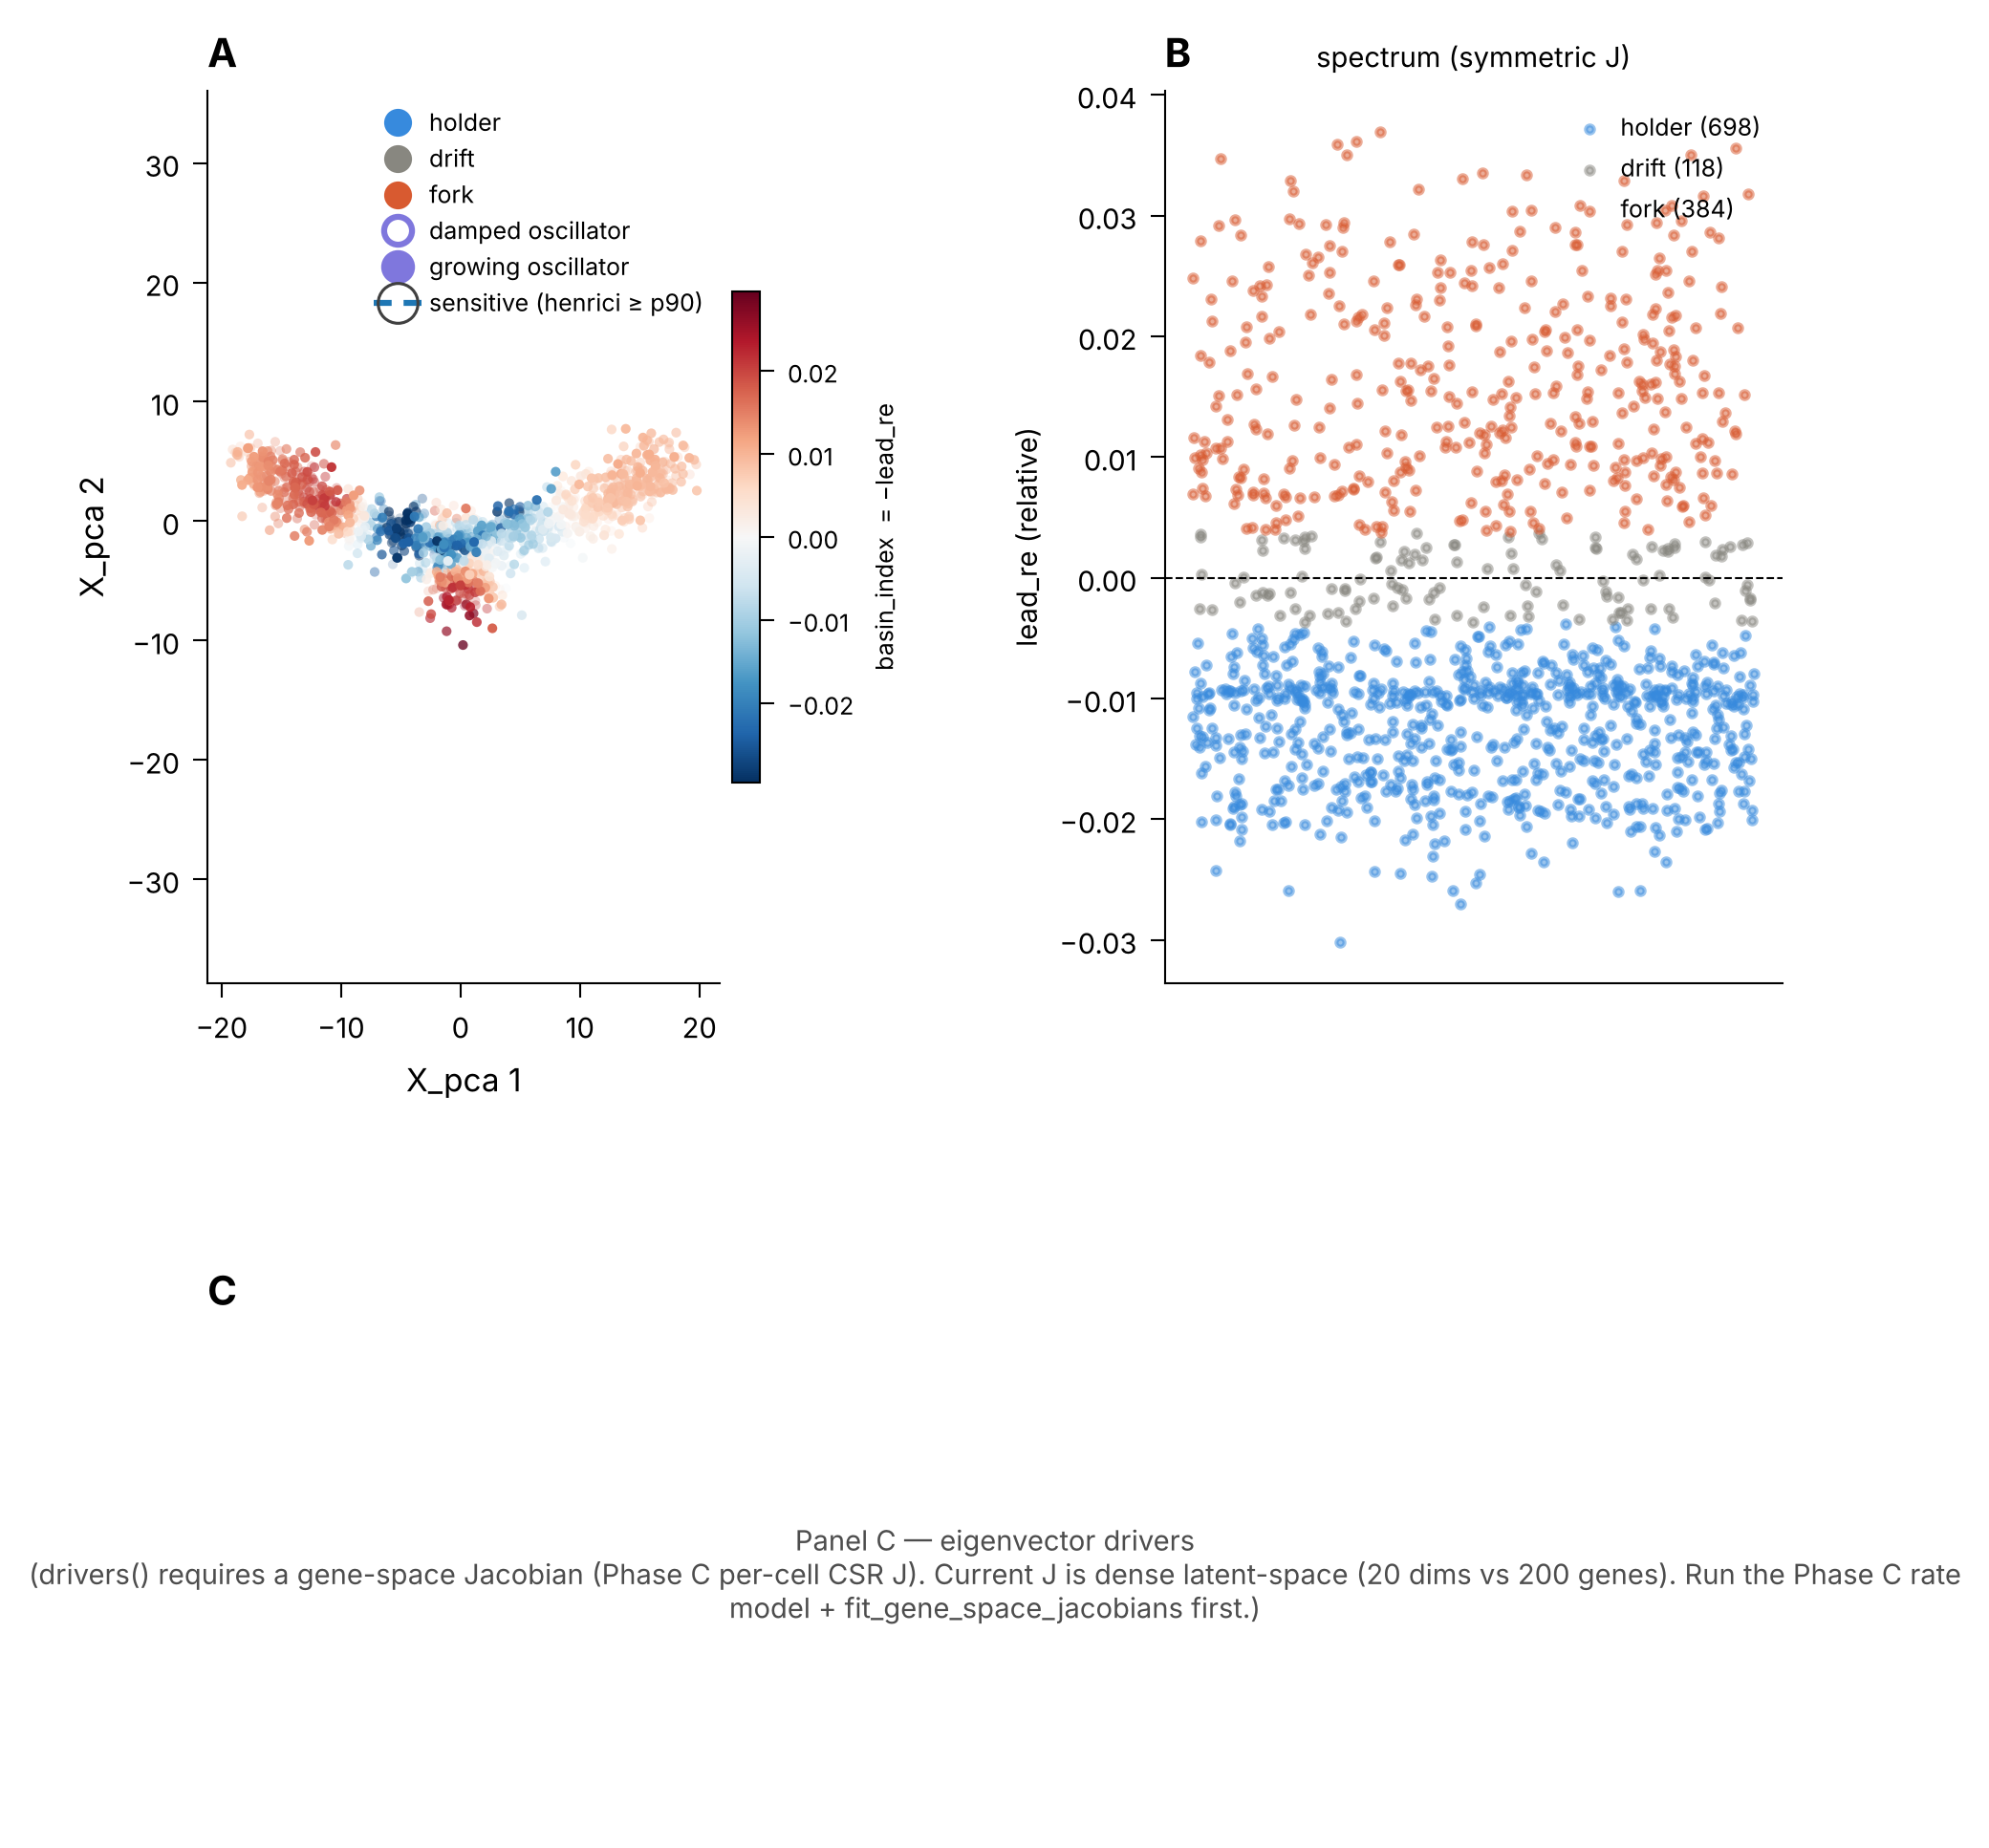

In [9]:
display(Image(filename=str(OUT / "operator_space.png"), width=760)) if "operator_space" in paths else print("operator_space: skipped")

### `ternary`

Panel A: each cell by the fraction of its eigenvalues below −tol / within ±tol / above +tol. Panel B: the same three fractions per cluster, early vs late.

Note the pile-up at the holder corner: the pitchfork is a 2-D system embedded in 20 PCA dimensions, so 18 axes are padding, all weakly contracting, and at most 1/20 of a cell's eigenvalues can be positive. This is the PCA tangent-rank ceiling (SUMMARY §5.6b) made visible; on real data with an anisotropic embedding the cloud spreads. The late saddle cells still carry the largest fork share, as they should.

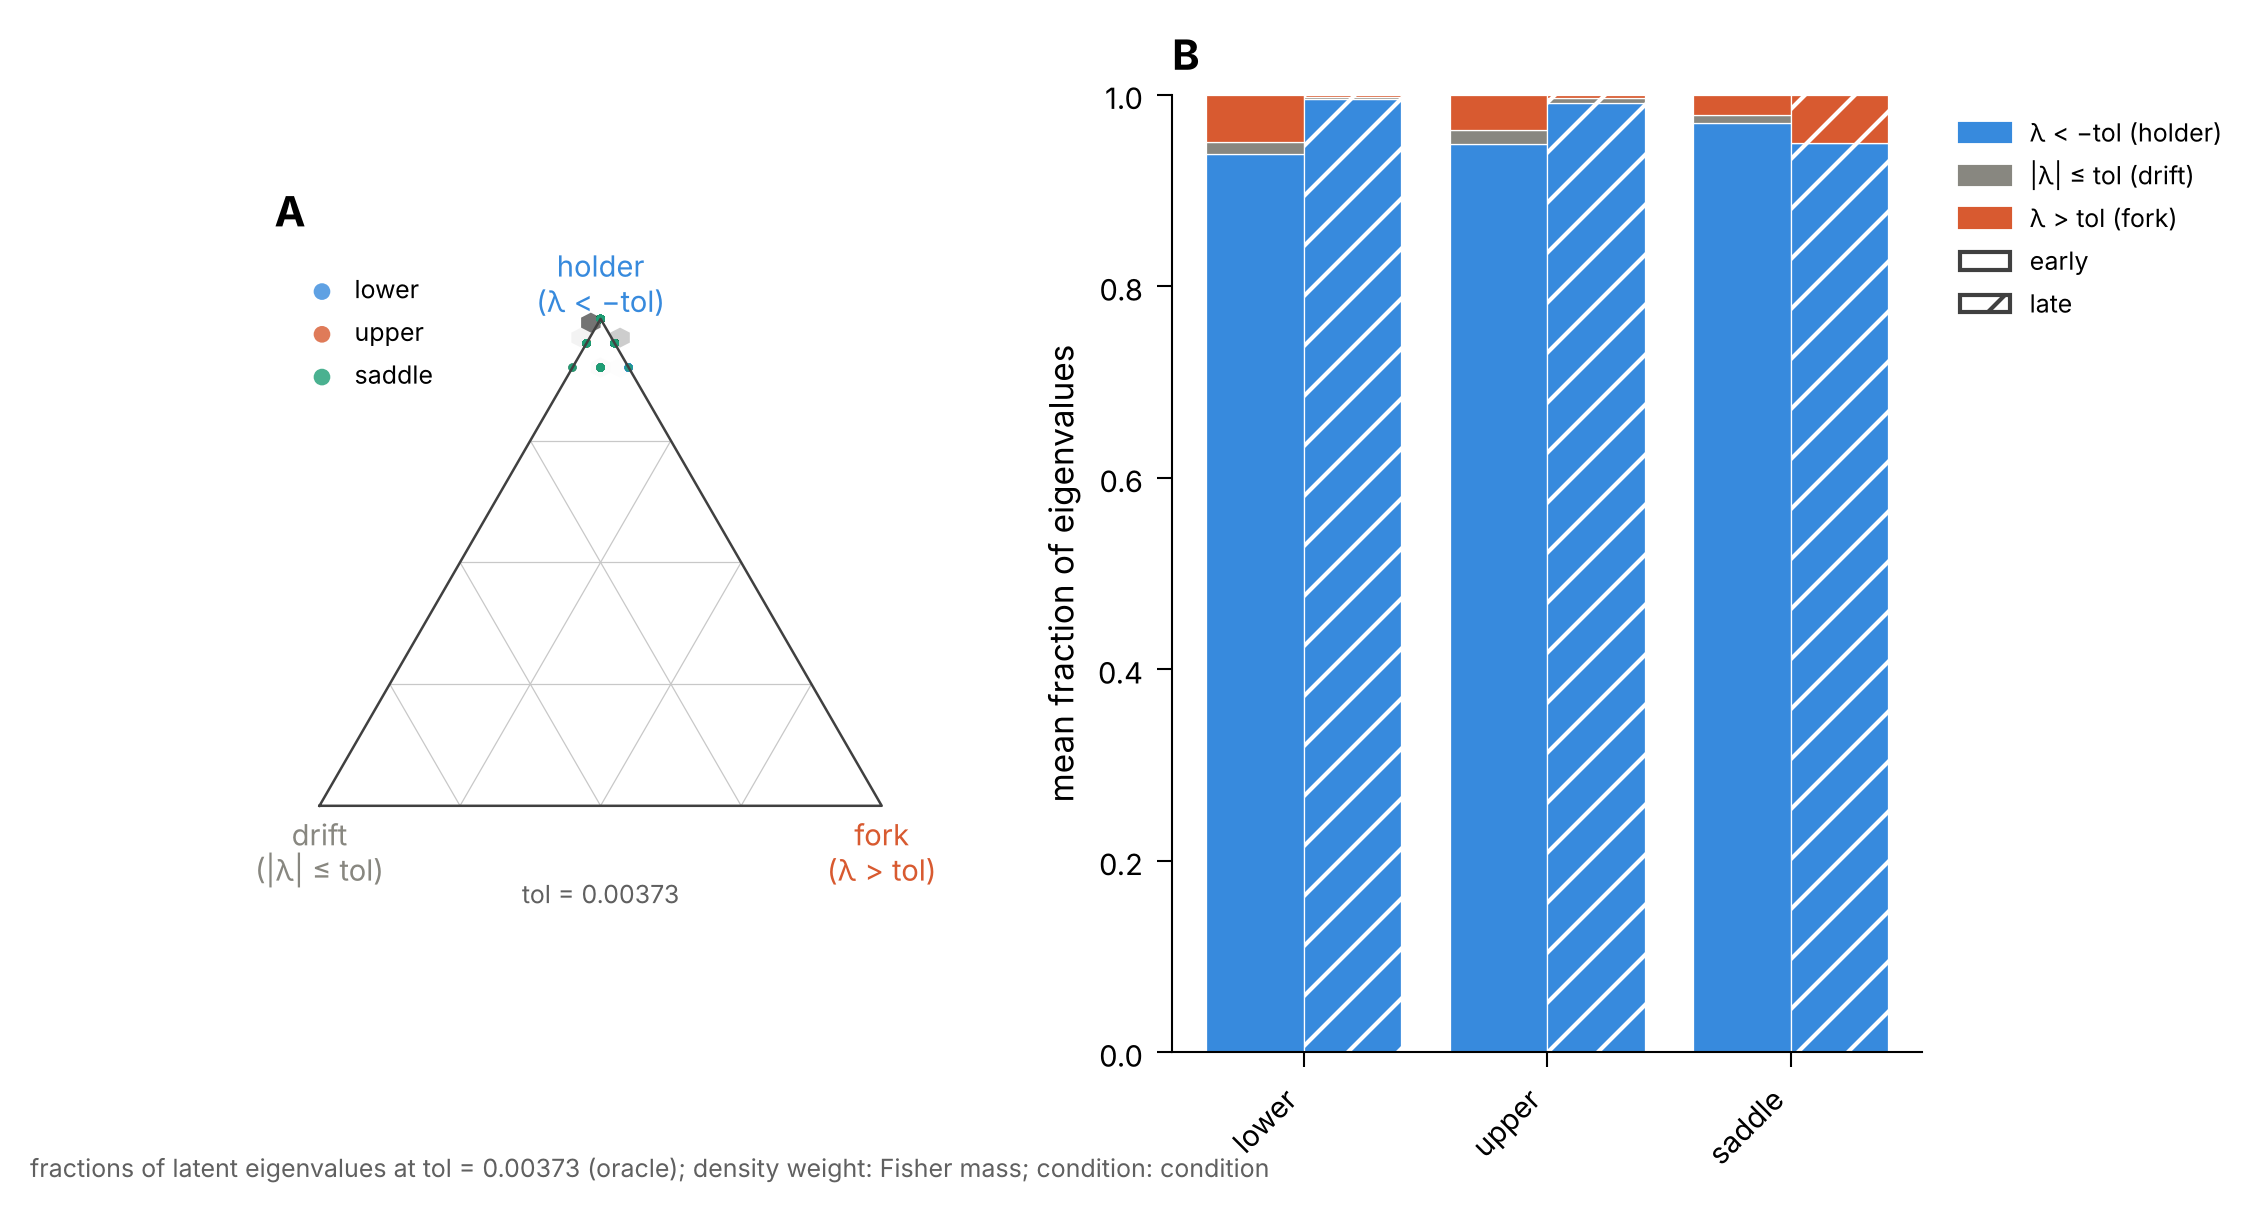

In [10]:
display(Image(filename=str(OUT / "ternary.png"), width=760)) if "ternary" in paths else print("ternary: skipped")

### `landscape`

Fisher-weighted density on the (lead_re, spectral gap) plane; dashed grey = scrambled null.

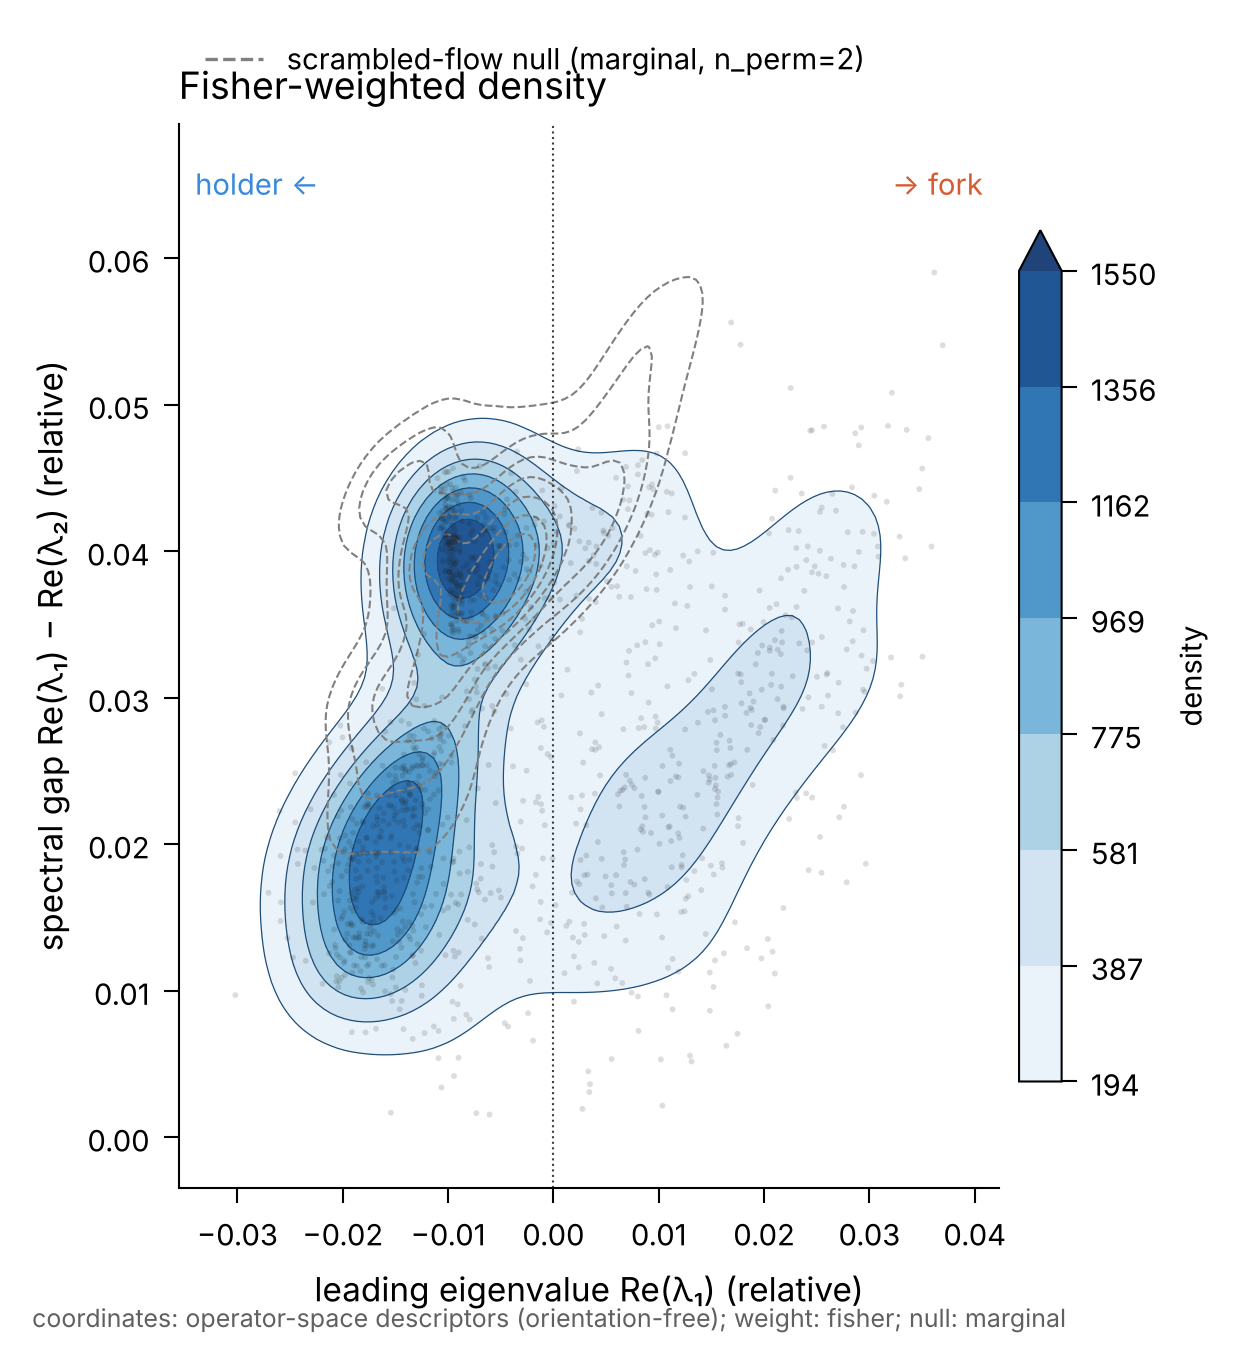

In [11]:
display(Image(filename=str(OUT / "landscape.png"), width=760)) if "landscape" in paths else print("landscape: skipped")

### `landscape_3d`

Same floor; bars = well stiffness per bin (depth along the holding directions), shade = occupancy. Tall-but-sparse and crowded-but-shallow regions are the point.

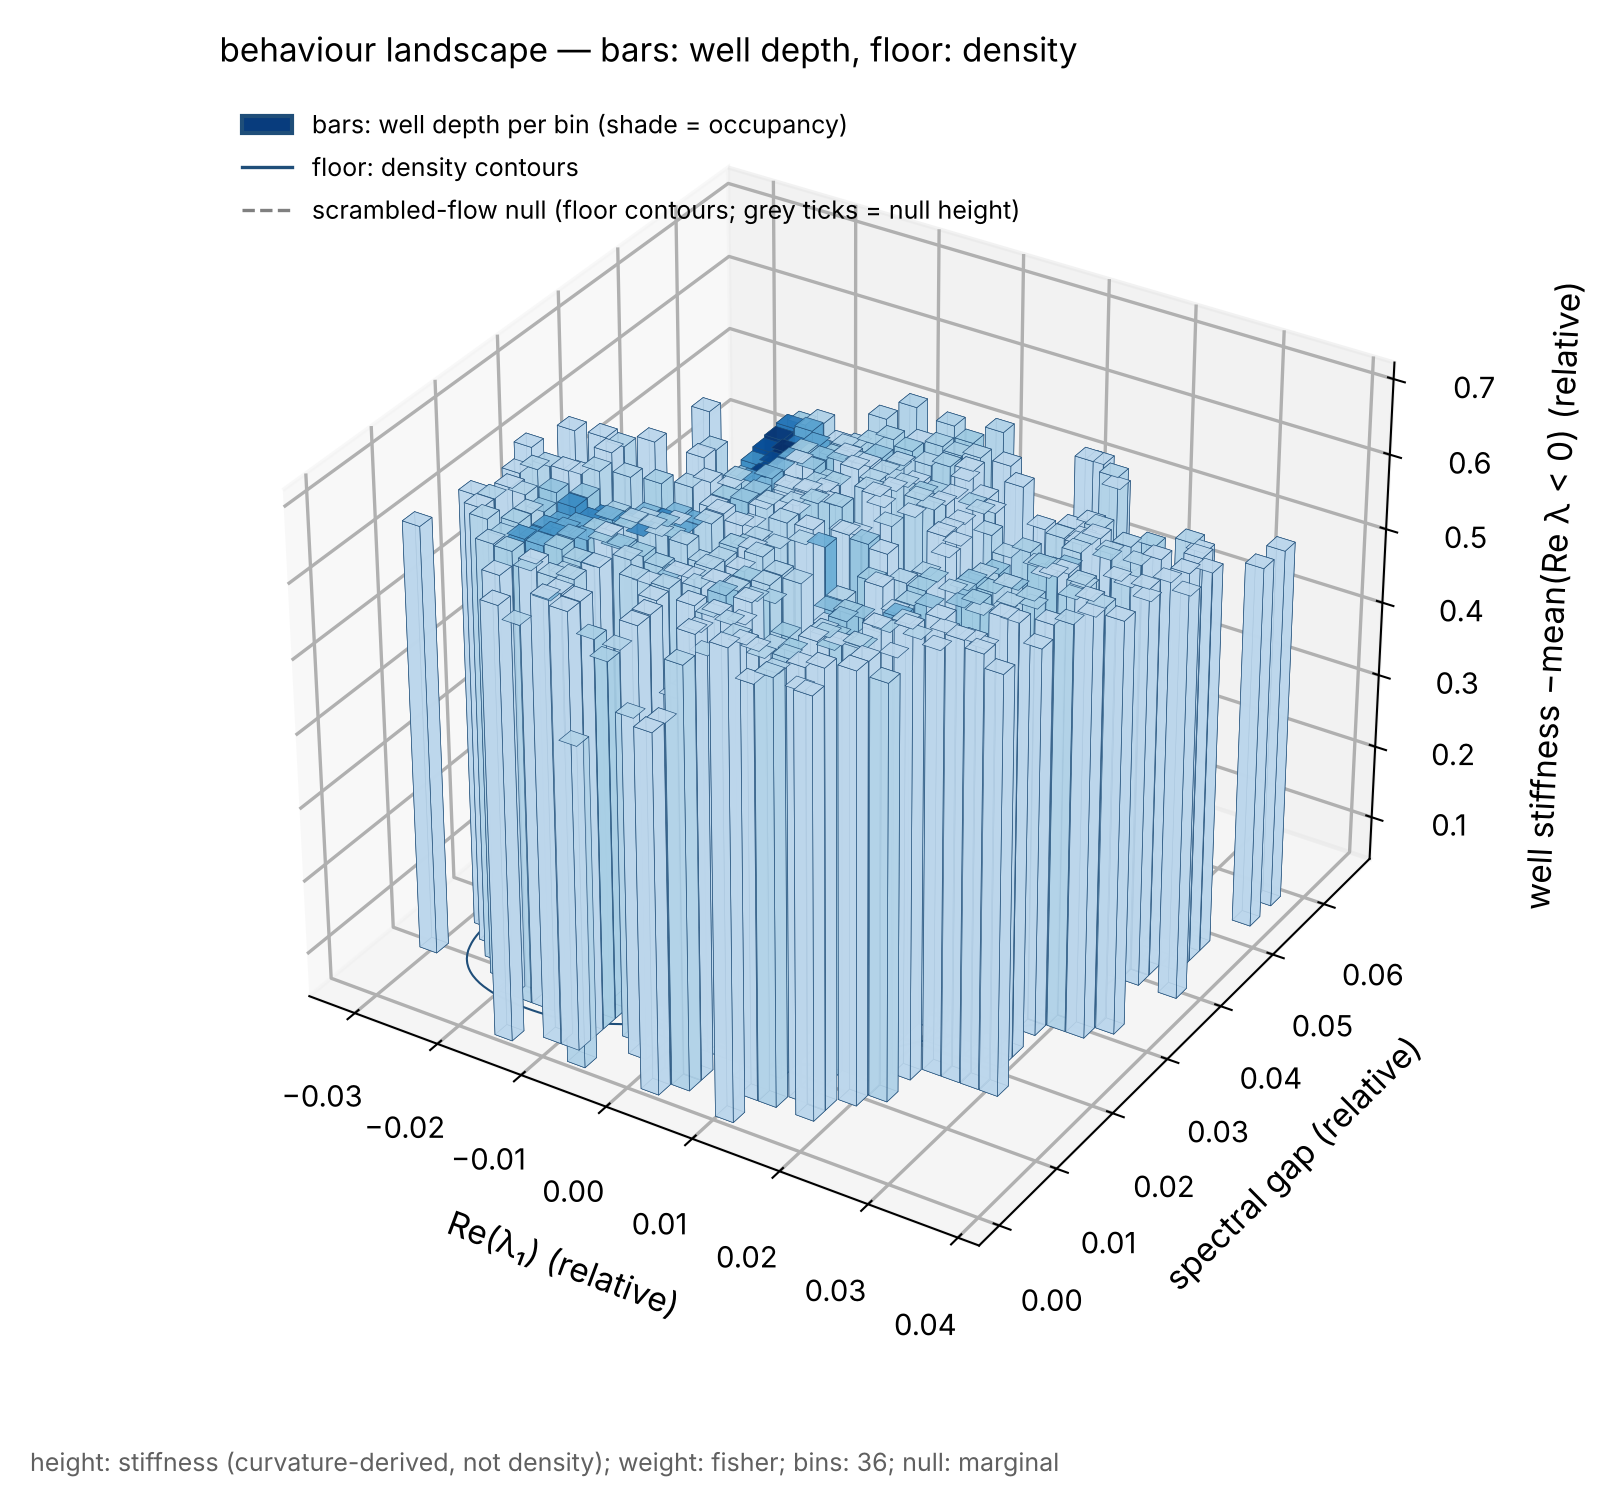

In [12]:
display(Image(filename=str(OUT / "landscape_3d.png"), width=760)) if "landscape_3d" in paths else print("landscape_3d: skipped")

### `energy`

The Waddington view: E(z) over the true 2-D state. Valleys = where cells pile up.

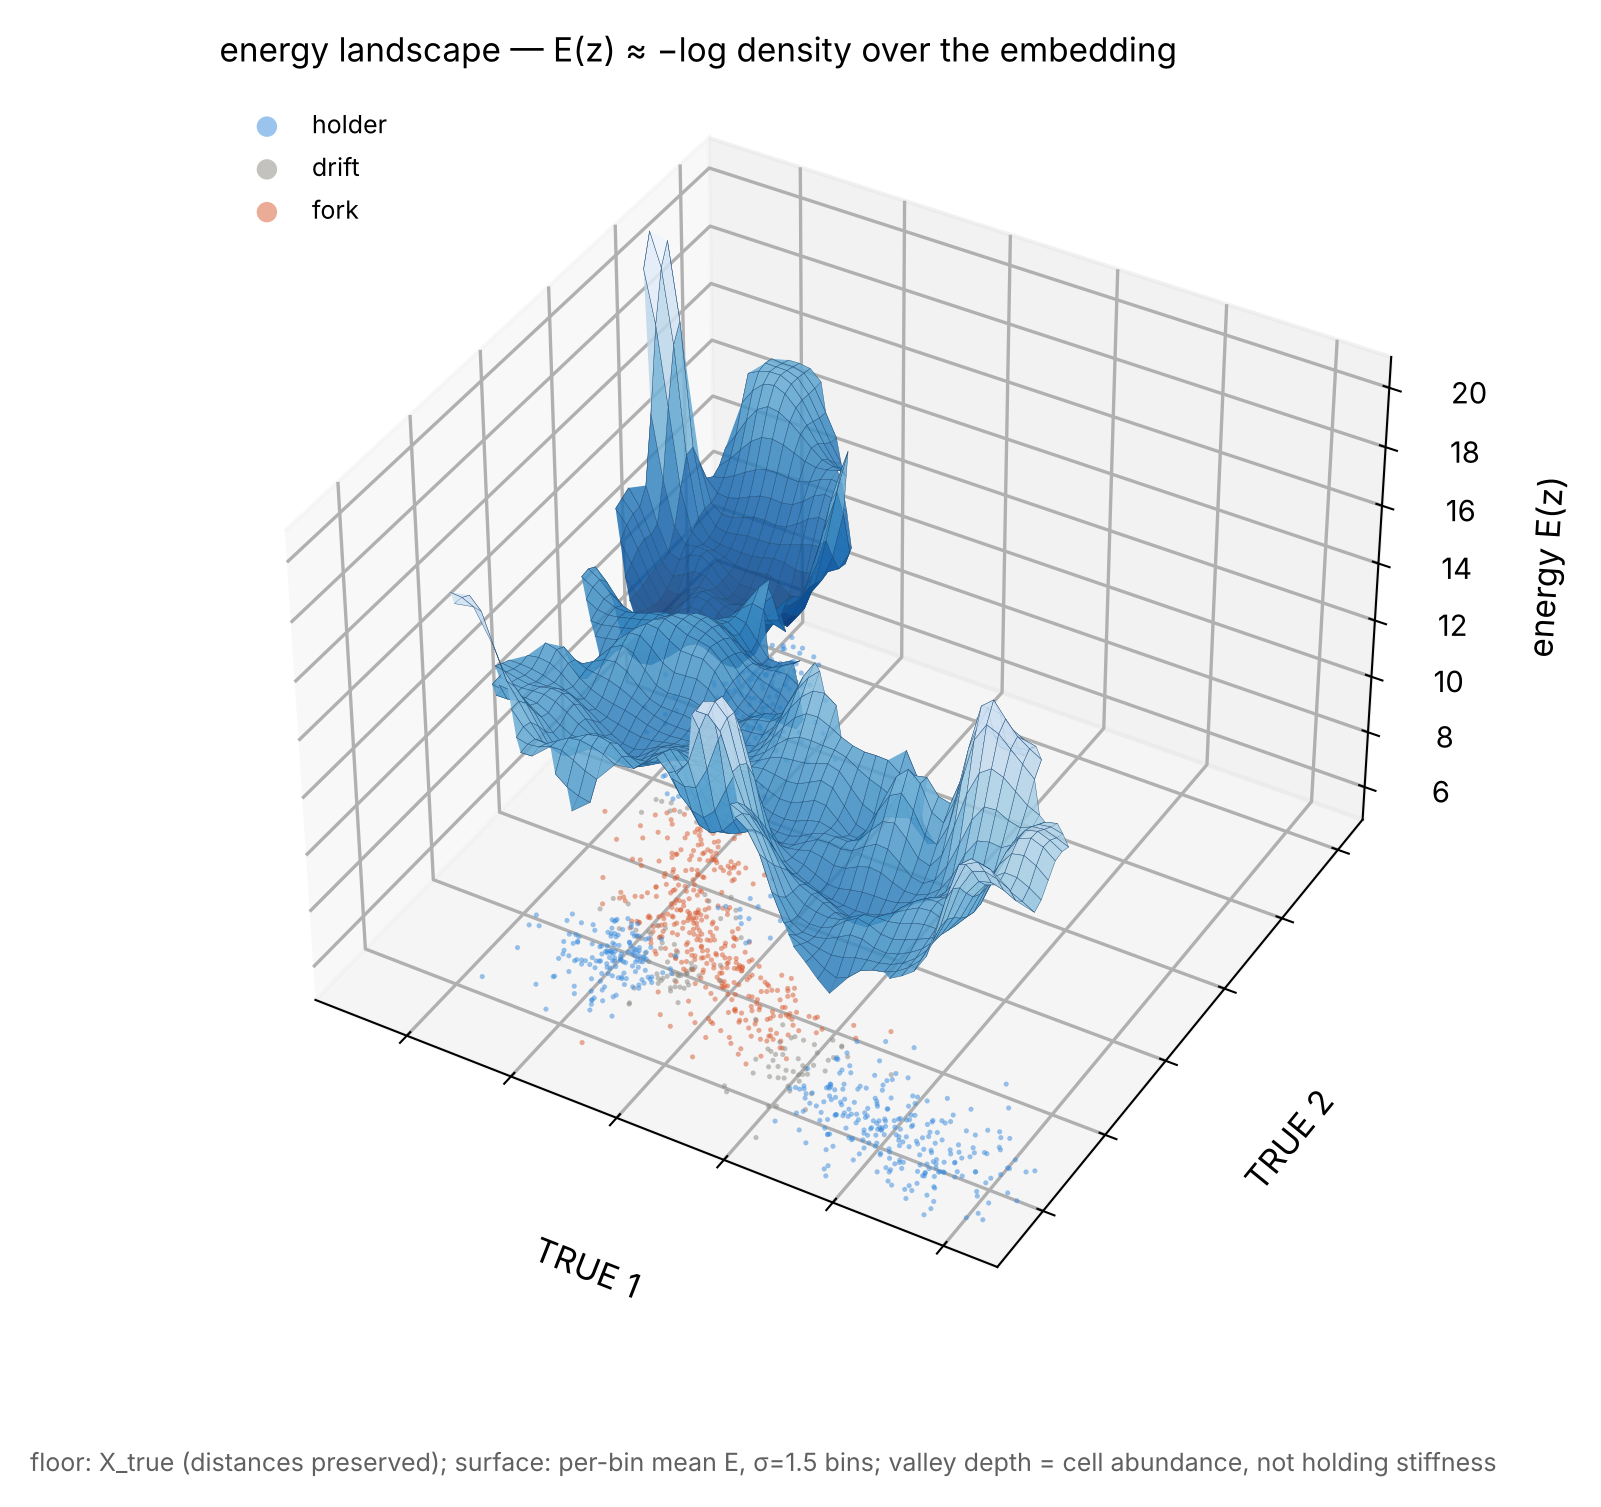

In [13]:
display(Image(filename=str(OUT / "energy.png"), width=760)) if "energy" in paths else print("energy: skipped")

### `motifs`

Motif × context occurrence matrix: rows are spectral motifs, columns are cluster contexts, filled where enriched above the shuffled-context null.

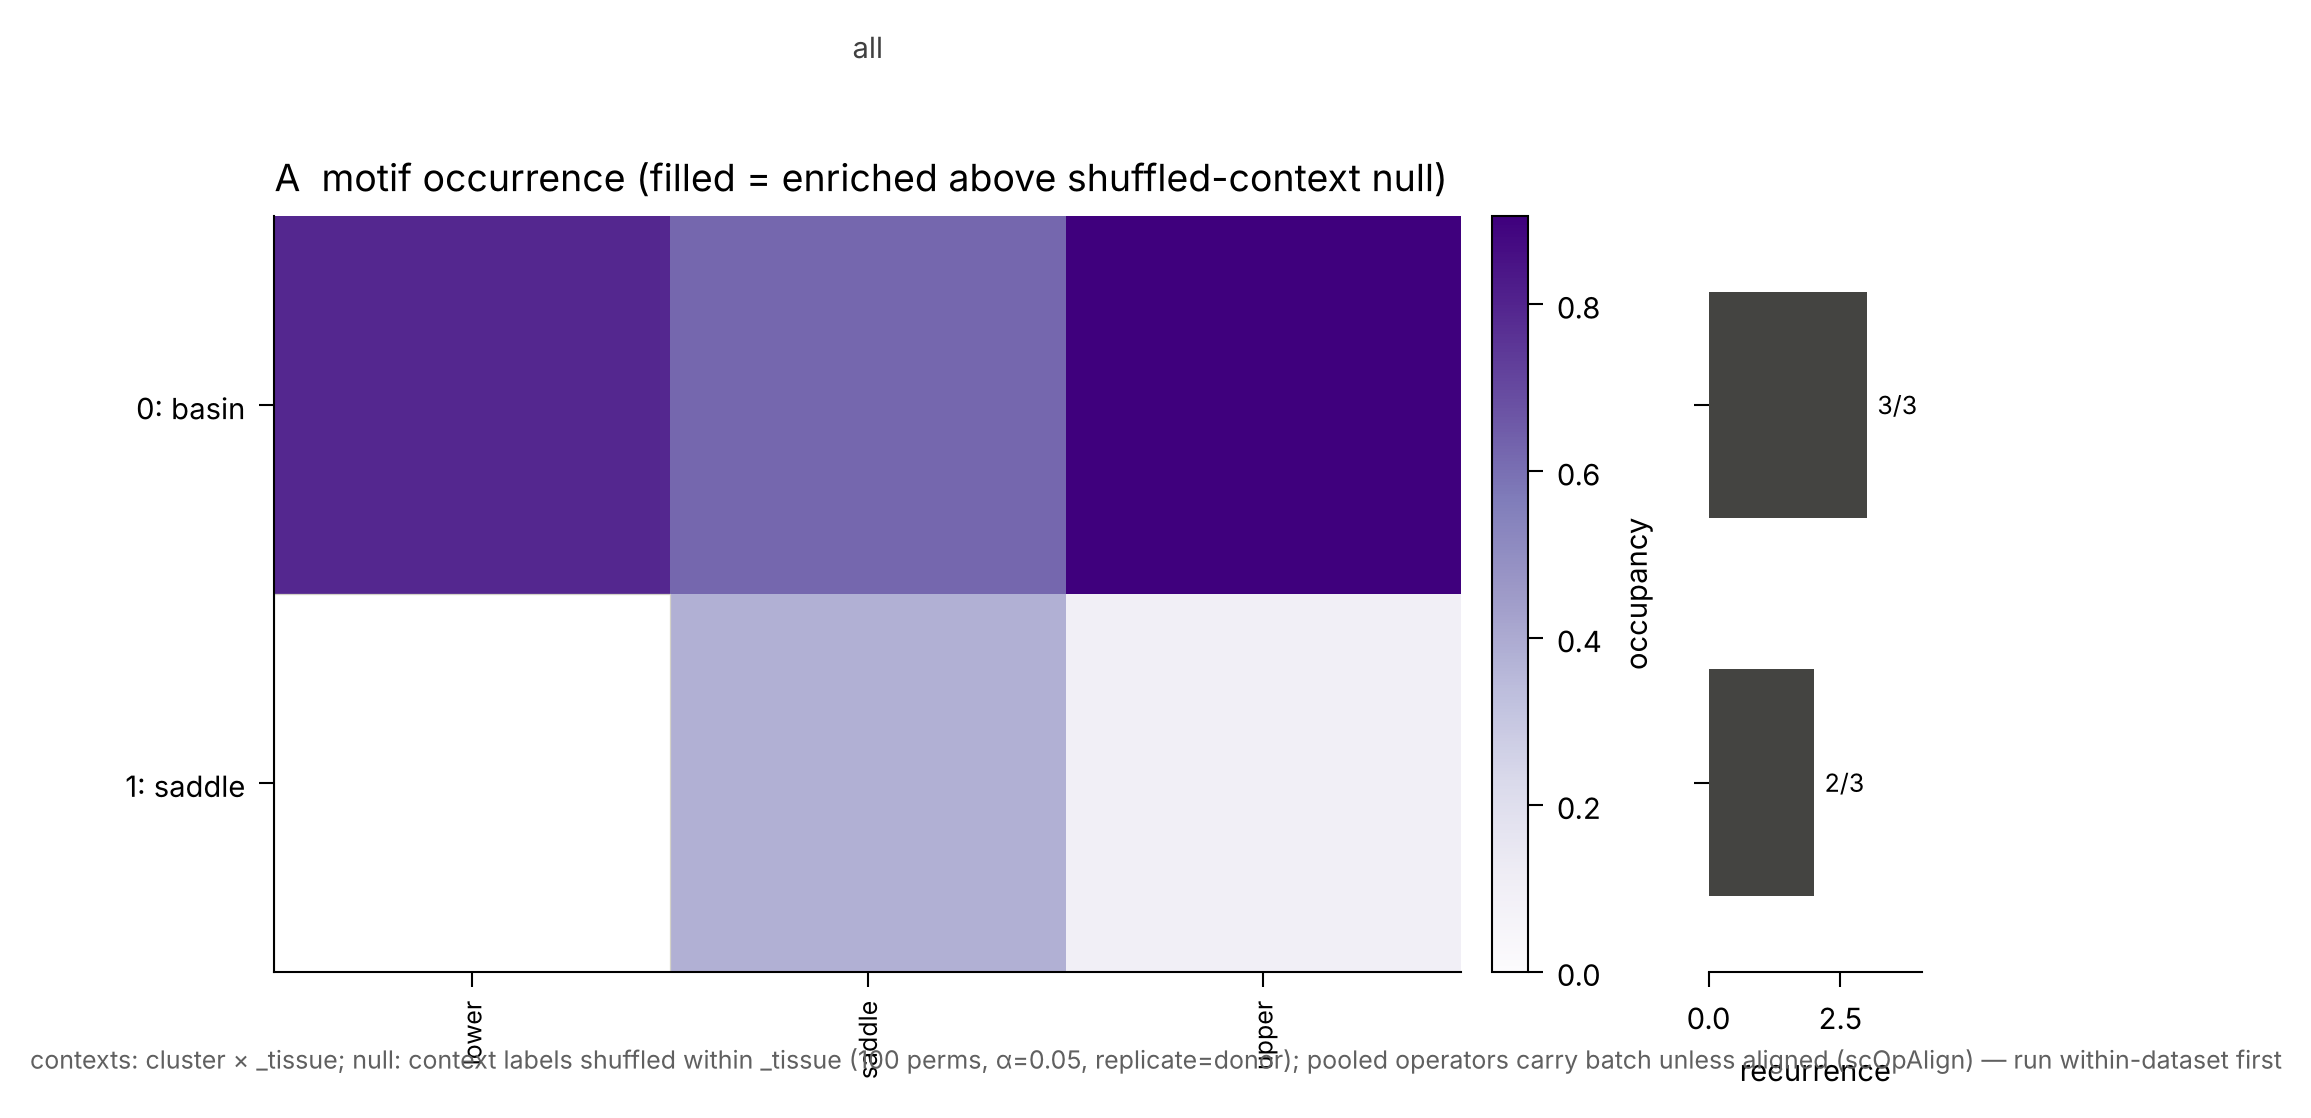

In [14]:
display(Image(filename=str(OUT / "motifs.png"), width=760)) if "motifs" in paths else print("motifs: skipped")

## 6. The same thing step by step

If you want one figure with different options, call the pieces directly.

In [15]:
from scjdo2.plot import figure_behaviour_landscape_3d, figure_behaviour_ternary

fig = figure_behaviour_landscape_3d(adata, y="spectral_gap", height="lambda_min", null=null)
plt.show()
fig = figure_behaviour_ternary(adata, color_key="cluster", condition_key="condition")
plt.show()

In [16]:
adata.uns["scjdo2"]["motifs"]["summary"]

,motif,n,lead_re,stiffness,lambda_min
0,0,938,-0.006426,0.620882,-0.795460
1,1,262,0.012906,0.566343,-0.704256


In [17]:
occ = adata.uns["scjdo2"]["motifs"]["occurrence"]
occ[occ["enriched"]].sort_values(["motif", "context"])

,motif,context,n,occupancy,null_mean,null_q,enriched,cluster,_tissue
0,0,lower | all,428,0.78926,0.781119,0.781119,True,lower,all
2,0,saddle | all,347,0.62056,0.000000,0.000000,True,saddle,all
4,0,upper | all,425,0.90573,0.000000,0.000000,True,upper,all
3,1,saddle | all,347,0.37944,0.000000,0.000000,True,saddle,all
5,1,upper | all,425,0.09427,0.000000,0.000000,True,upper,all
